<h1> Loading data <h1>

In [13]:
from tda_modulev3 import CloudDataManager

manager = CloudDataManager()
filepath = "/workspaces/TDA-workspace/data/Point clouds-selected/control name=embryo_3.csv"
filepath2 = "/workspaces/TDA-workspace/data/Point clouds-selected/epha2a hom name=embryo_4.csv"
filepath3 = "/workspaces/TDA-workspace/data/Point clouds-selected/control WT  full video centroids_table name=embryo_1.csv"
ids = manager.load_group_from_file(filepath)
ids2 = manager.load_group_from_file(filepath2)
ids3 = manager.load_group_from_file(filepath3)
# display answers in a table for 10 by 6
print("Loaded IDs:")
for i, id in enumerate([*ids, *ids2, *ids3]):
    print(f"{id}", end=" \t")
    if (i + 1) % 5 == 0:
        print()  # New line after every 5 IDs

Loaded IDs:
('embryo_3', 0) 	('embryo_3', 8) 	('embryo_3', 16) 	('embryo_3', 24) 	('embryo_3', 32) 	
('embryo_3', 40) 	('embryo_3', 48) 	('embryo_3', 56) 	('embryo_4', 0) 	('embryo_4', 8) 	
('embryo_4', 16) 	('embryo_4', 24) 	('embryo_4', 32) 	('embryo_4', 40) 	('embryo_4', 48) 	
('embryo_4', 56) 	('embryo_1', 0) 	('embryo_1', 8) 	('embryo_1', 16) 	('embryo_1', 24) 	
('embryo_1', 32) 	('embryo_1', 40) 	('embryo_1', 48) 	('embryo_1', 56) 	

<h2> Checking data Structure <h2>

In [14]:
# manager.groups[("embryo_1", 50)]


<h3> Calculating Diagrams and Landscapes <h3>

In [15]:
help(manager.TDA.compute_all_persistence_diagrams)
manager.TDA.compute_all_persistence_diagrams()
help(manager.TDA.compute_all_persistence_landscapes)
manager.TDA.compute_all_persistence_landscapes(n_layers=2,resolution=500)
manager._tda_params


Help on method compute_all_persistence_diagrams in module tda_modulev3:

compute_all_persistence_diagrams(
    max_dimension: int = 2,
    max_edge_length: Optional[float] = inf,
    homology_coeff_field: int = 2,
    min_persistence: float = 0.0
) -> 'CloudDataManager' method of tda_modulev3.CloudGroupTDA instance
    Compute persistence diagrams for every loaded CloudGroup.

Help on method compute_all_persistence_landscapes in module tda_modulev3:

compute_all_persistence_landscapes(
    min_persistence: float = 0.0,
    resolution: int = 100,
    n_layers: int = 5
) -> 'CloudDataManager' method of tda_modulev3.CloudGroupTDA instance
    Compute landscapes for every group using already-computed diagrams.



{'max_dimension': 2,
 'max_edge_length': inf,
 'homology_coeff_field': 2,
 'min_persistence': 0.0,
 'dimensions': [0, 1],
 'resolution': 500,
 'n_layers': 2}

<h3> Persistance Diagramsn and Landscape Plots <h3>

<h4> Get a group <h4>

<h4> Plots <h4>

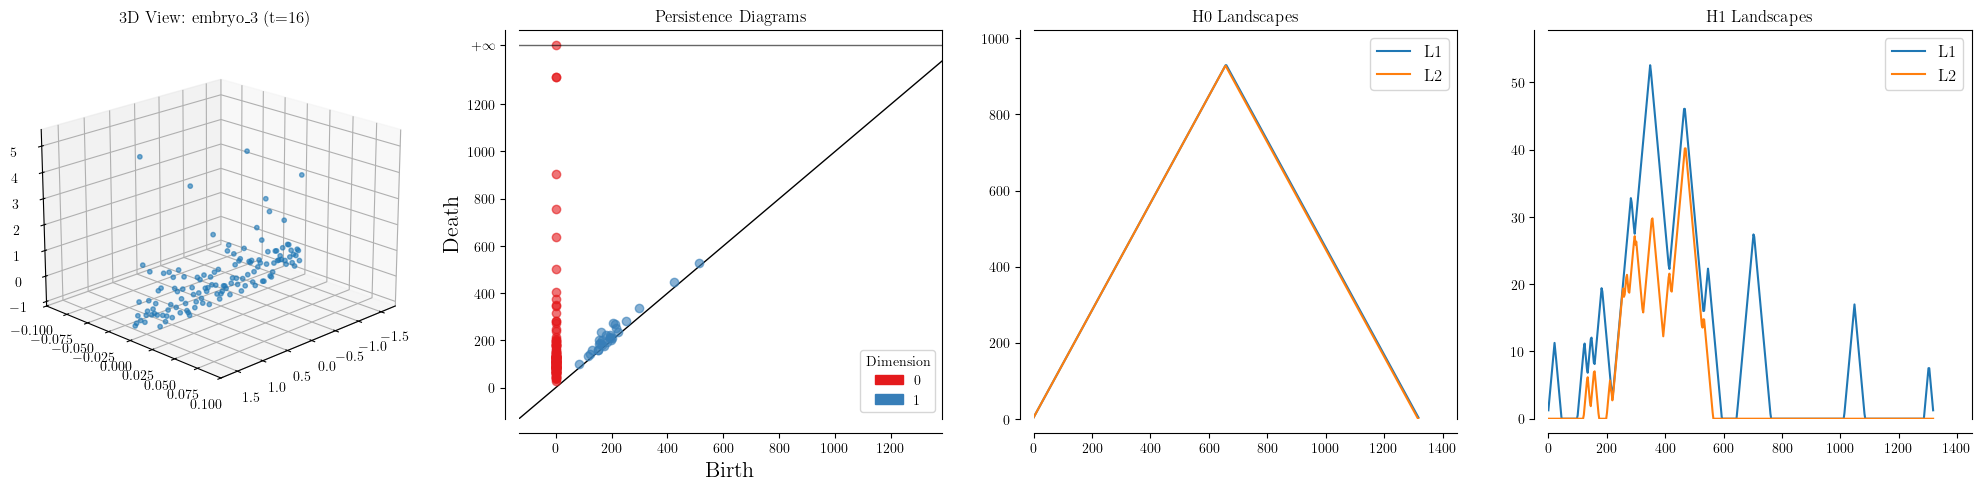

In [16]:
manager.Plotter.compare_tda_summaries([("embryo_3", 16)], shared_axes=False)

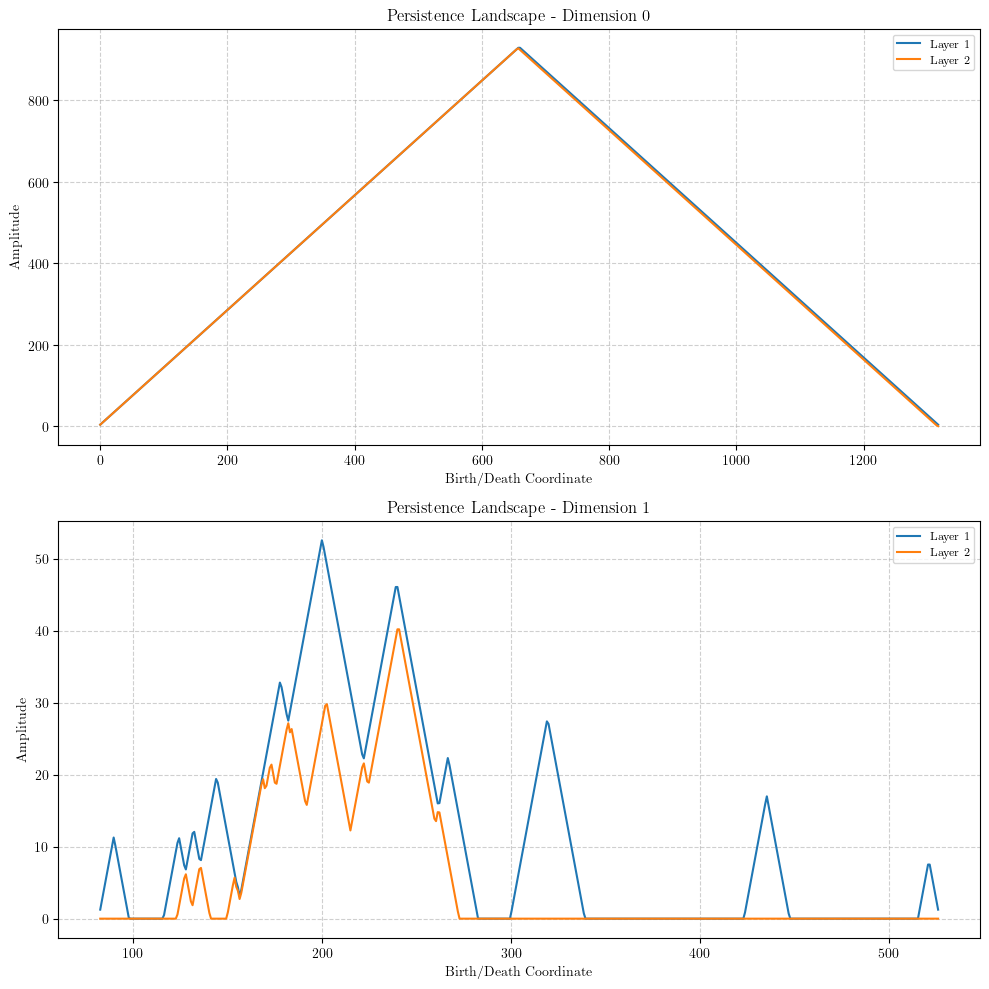

In [17]:
fig = manager.Plotter.plot_persistence_landscapes(manager.groups[("embryo_3",16)].landscapes, )
fig

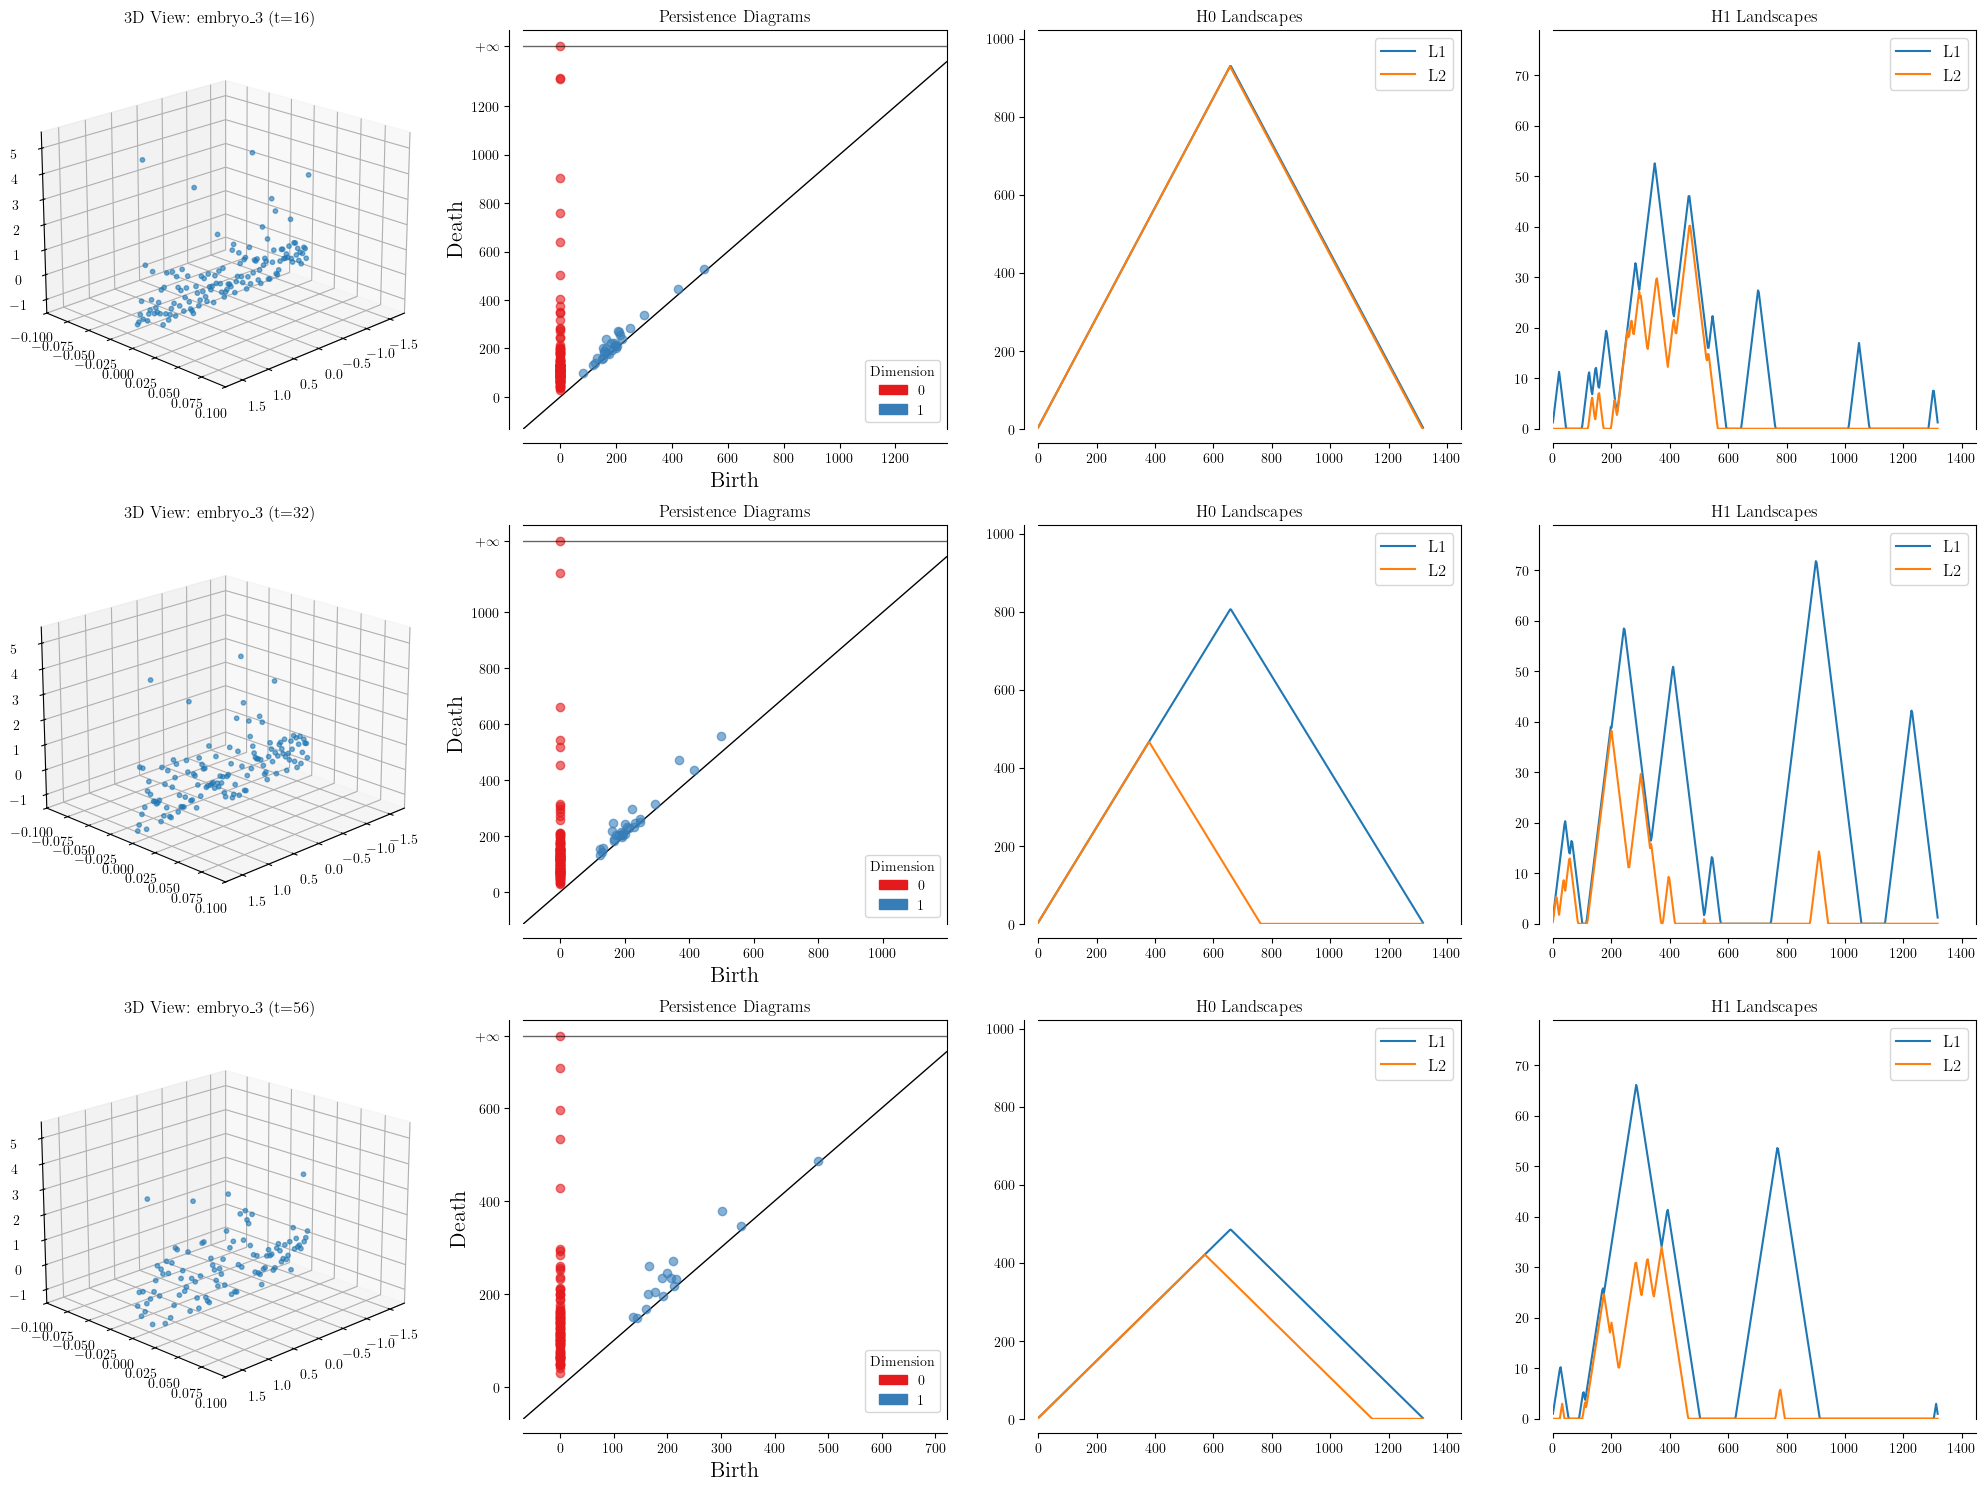

In [18]:
fig = manager.Plotter.compare_tda_summaries([("embryo_3", 16), ("embryo_3", 32), ("embryo_3", 56)], shared_axes=False)
fig

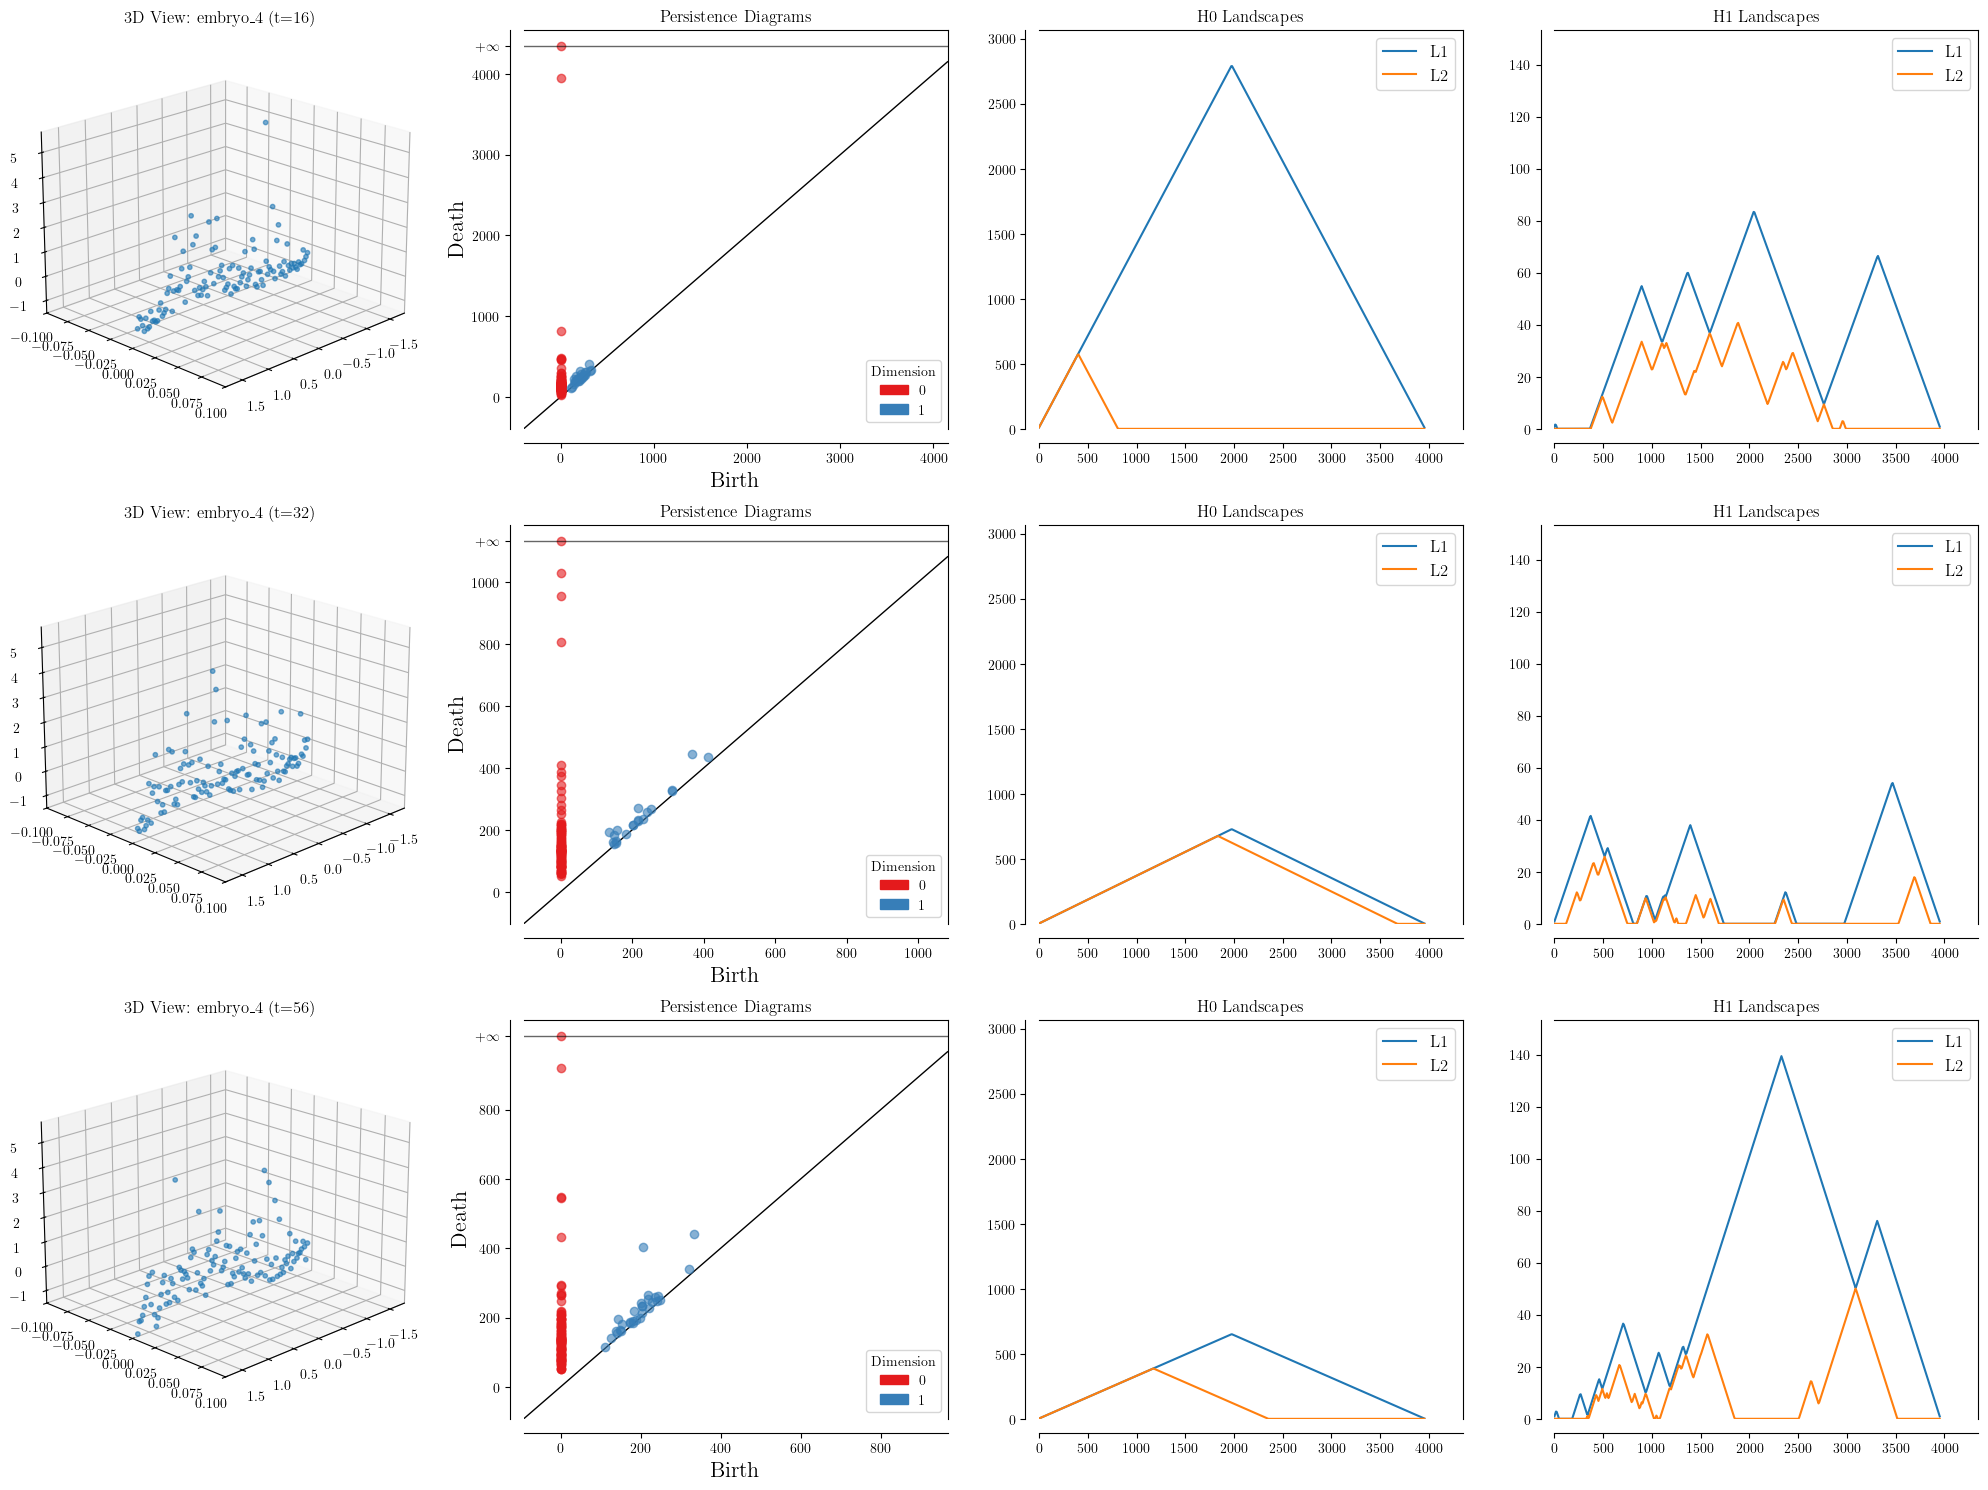

In [19]:
fig = manager.Plotter.compare_tda_summaries([("embryo_4",16), ("embryo_4",32), ("embryo_4",56)], shared_axes=False)
fig

<h2> PCA Analsys <h2>

In [20]:
manager.PCA.run(properties=[0,1])
manager.PCA.run(properties=[0])
manager.PCA.run(properties=[1])

{'transformed': array([[-14.76416549, -11.38795026],
        [ 11.58622805,  -6.96270252],
        [ -4.64830455, -26.5584333 ],
        [ -5.87094723,  -6.45987185],
        [  6.00353737,   2.59215915],
        [ -1.02638072, -16.60650336],
        [ -2.87503447,  -9.69501045],
        [-16.28148483,  -3.21420707],
        [ -0.10560657,  -7.0779849 ],
        [ -4.21140293,  18.43048918],
        [ -6.73177544,   0.24327571],
        [ -5.80070232,   6.75084224],
        [ -2.86846452,  11.86886186],
        [-17.71589893,  11.2933772 ],
        [ 17.33891417,  23.63712417],
        [ -7.63352106,   5.90825857],
        [ -0.49563743,  -3.10294678],
        [ -4.17845856,  -9.85531443],
        [ 26.77907743, -10.83825304],
        [-14.55061732,  -0.75281799],
        [ -9.06931126,   7.49556618],
        [ 13.65797977,  27.40162098],
        [ -6.62819728,   5.08745964],
        [ 50.09017412,  -8.19703894]]),
 'explained_variance_ratio': array([0.22091064, 0.15669712]),
 'row_ord

{np.float64(56.29719753484267), np.float64(28.565830426287903)}


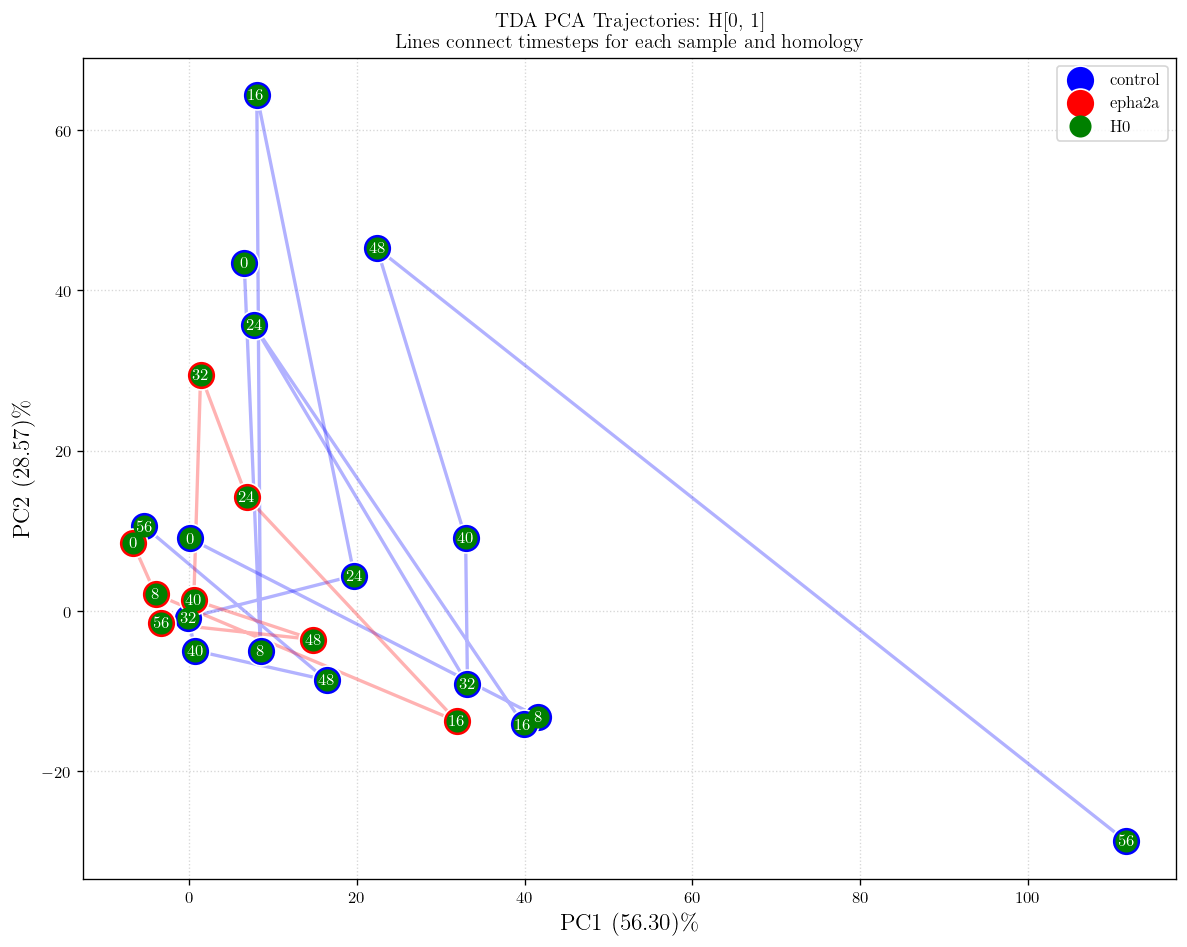

In [30]:
manager.PCA.plot_trajectories(properties=[0,1], do_not_include={"properties":[1],"condition":[""]})

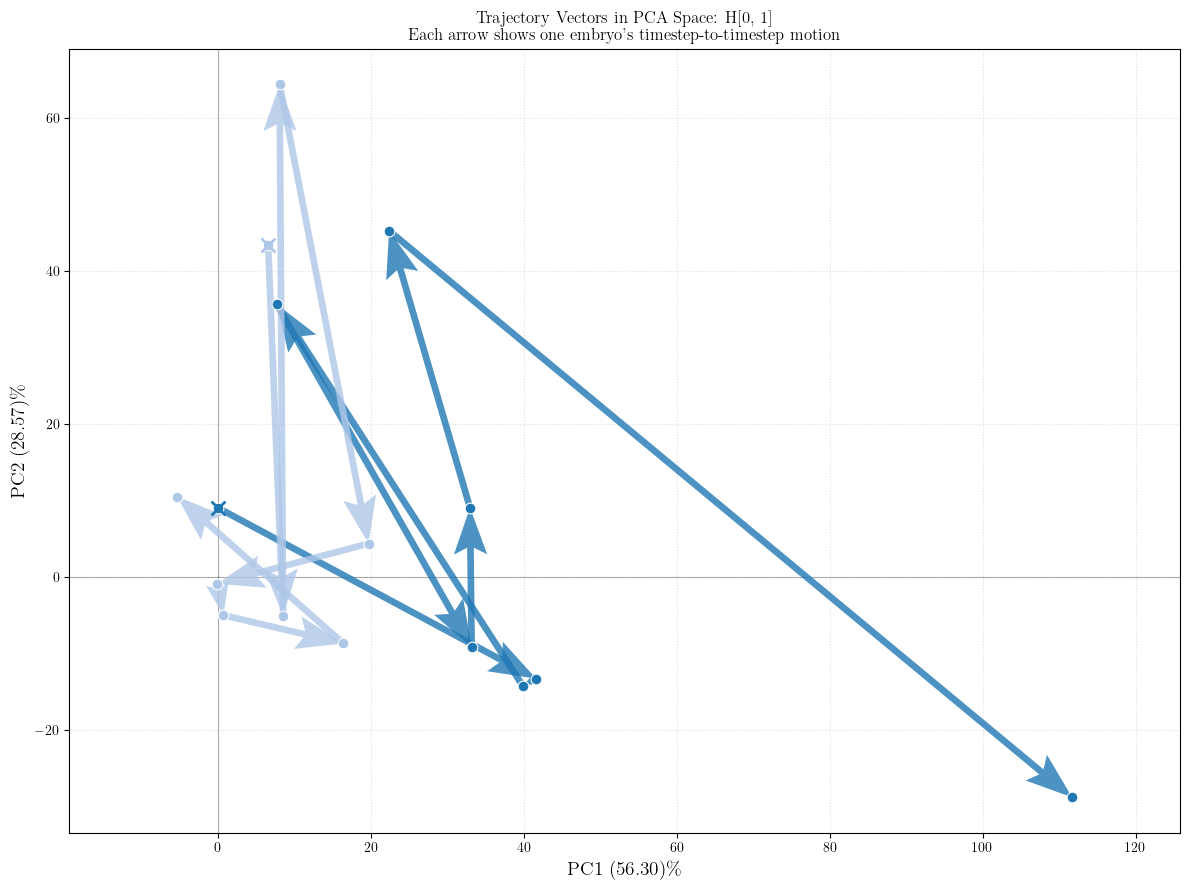

In [31]:
manager.PCA.plot_trajectory_vectors(properties=[0,1], do_not_include={"properties":[1], "condition":["epha2a"],"embryo_names":[""]})



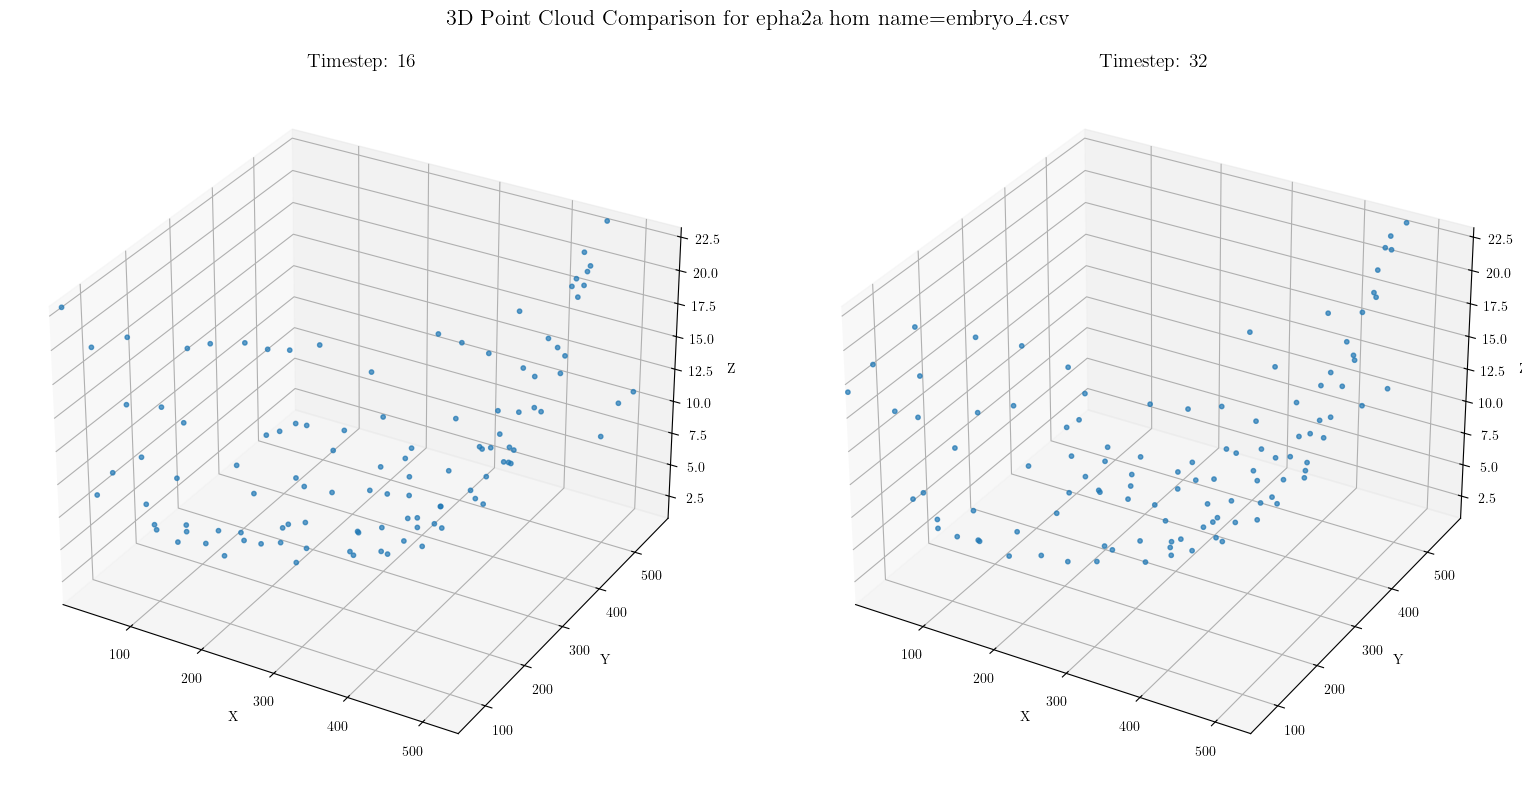

In [23]:
import os
import pandas as pd
import matplotlib.pyplot as plt
def visualize_point_clouds_side_by_side(file_path: str, ts1: int, ts2: int):
    """
    Generates side-by-side 3D scatter plots for two timesteps from the same file.
    
    Args:
        file_path: The absolute path to the CSV file.
        ts1: The first timestep to plot.
        ts2: The second timestep to plot.
    """
    if not os.path.exists(file_path):
        print(f"Error: File not found at {file_path}")
        return

    try:
        df = pd.read_csv(file_path)
        
        # --- Prepare Data ---
        df = df.rename(columns={
            "Center of the object_0": "x",
            "Center of the object_1": "y",
            "Center of the object_2": "z",
        })
        
        data1 = df[df['timestep'] == ts1]
        data2 = df[df['timestep'] == ts2]

        if data1.empty or data2.empty:
            print(f"Error: Data for one or both timesteps ({ts1}, {ts2}) not found.")
            return

        # --- Create Plot ---
        fig = plt.figure(figsize=(16, 8))
        fig.suptitle(f"3D Point Cloud Comparison for {os.path.basename(file_path)}", fontsize=16)

        # --- First Subplot ---
        ax1 = fig.add_subplot(1, 2, 1, projection='3d')
        ax1.scatter(data1['x'], data1['y'], data1['z'], s=10, alpha=0.7)
        ax1.set_title(f"Timestep: {ts1}", fontsize=14)
        ax1.set_xlabel("X")
        ax1.set_ylabel("Y")
        ax1.set_zlabel("Z")

        # --- Second Subplot ---
        ax2 = fig.add_subplot(1, 2, 2, projection='3d')
        ax2.scatter(data2['x'], data2['y'], data2['z'], s=10, alpha=0.7)
        ax2.set_title(f"Timestep: {ts2}", fontsize=14)
        ax2.set_xlabel("X")
        ax2.set_ylabel("Y")
        ax2.set_zlabel("Z")
        
        # --- Synchronize Axes for Direct Comparison ---
        # Find global min/max across both datasets to set shared axis limits
        x_min = min(data1['x'].min(), data2['x'].min())
        x_max = max(data1['x'].max(), data2['x'].max())
        y_min = min(data1['y'].min(), data2['y'].min())
        y_max = max(data1['y'].max(), data2['y'].max())
        z_min = min(data1['z'].min(), data2['z'].min())
        z_max = max(data1['z'].max(), data2['z'].max())

        ax1.set_xlim(x_min, x_max)
        ax1.set_ylim(y_min, y_max)
        ax1.set_zlim(z_min, z_max)
        
        ax2.set_xlim(x_min, x_max)
        ax2.set_ylim(y_min, y_max)
        ax2.set_zlim(z_min, z_max)

        plt.tight_layout(rect=[0, 0, 1, 0.96])
        plt.show()

    except Exception as e:
        print(f"An unexpected error occurred: {e}")

if __name__ == "__main__":
    target_file = '/workspaces/TDA-workspace/data/Point clouds-selected/epha2a hom name=embryo_4.csv'
    
    # Visualize the two timesteps of interest
    visualize_point_clouds_side_by_side(target_file, ts1=16, ts2=32)

<h1> 